In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
import pandas as pd
from src.data import load_data
from config import config
import numpy as np

train, test = load_data(config)
print(train.shape)
#print(train.head(3))

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(train.isna().sum().sort_values(ascending=False))
    #print(train.isna().sum().sort_values(ascending=False))
    #print(train.info())
print(train.dtypes.value_counts())


(1460, 81)


PoolQC           1453
MiscFeature      1406
Alley            1369
Fence            1179
MasVnrType        872
FireplaceQu       690
LotFrontage       259
GarageYrBlt        81
GarageCond         81
GarageType         81
GarageFinish       81
GarageQual         81
BsmtFinType2       38
BsmtExposure       38
BsmtQual           37
BsmtCond           37
BsmtFinType1       37
MasVnrArea          8
Electrical          1
Id                  0
Functional          0
Fireplaces          0
KitchenQual         0
KitchenAbvGr        0
BedroomAbvGr        0
HalfBath            0
FullBath            0
BsmtHalfBath        0
TotRmsAbvGrd        0
GarageCars          0
GrLivArea           0
GarageArea          0
PavedDrive          0
WoodDeckSF          0
OpenPorchSF         0
EnclosedPorch       0
3SsnPorch           0
ScreenPorch         0
PoolArea            0
MiscVal             0
MoSold              0
YrSold              0
SaleType            0
SaleCondition       0
BsmtFullBath        0
HeatingQC 

str        43
int64      35
float64     3
Name: count, dtype: int64


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


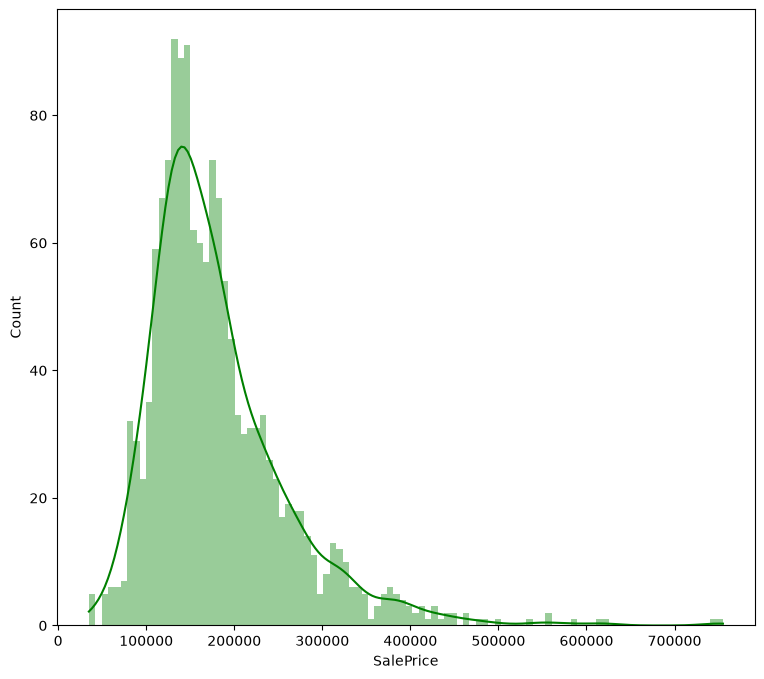

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sale_price = train['SalePrice']
print(sale_price.describe())
plt.figure(figsize=(9, 8))
sns.histplot(sale_price, color='g', bins=100, kde=True, alpha=0.4, edgecolor='none')
plt.show()

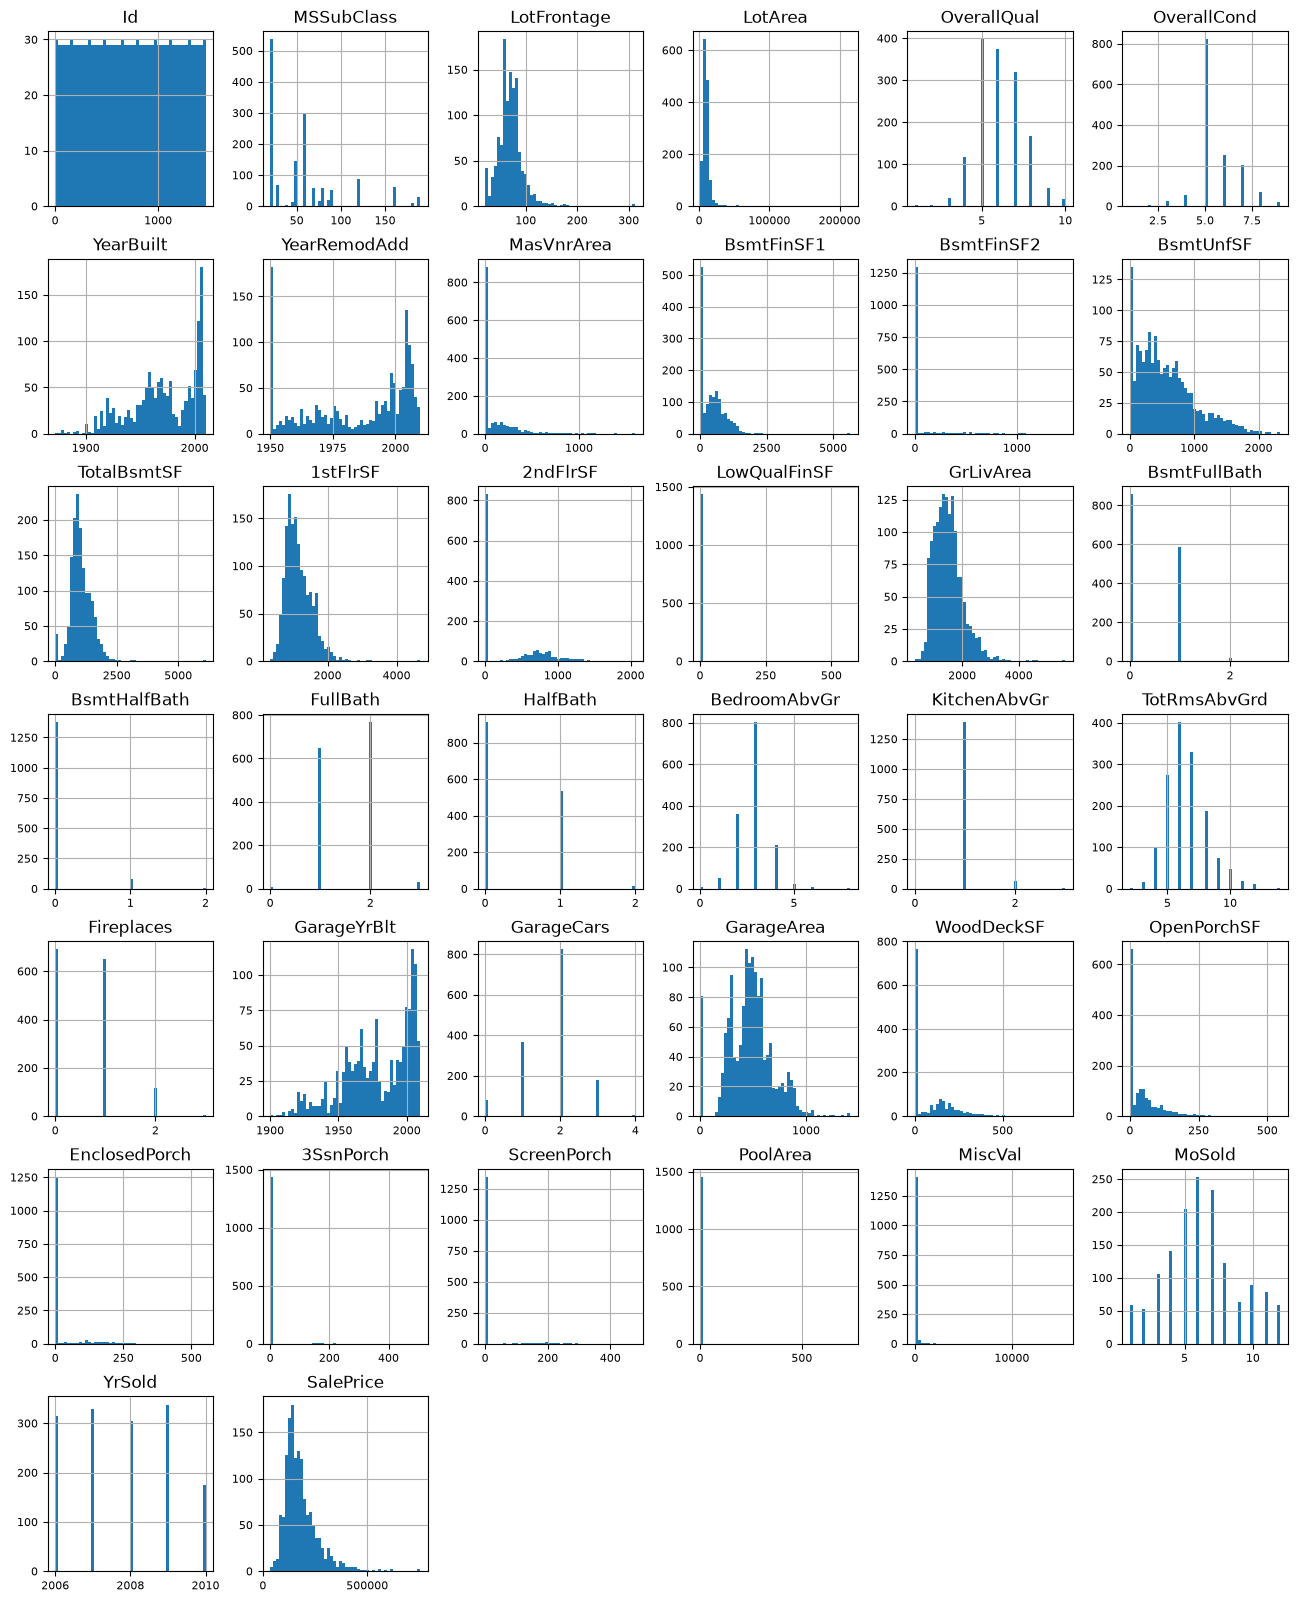

In [4]:
train_nums = train.select_dtypes(include=['float64', 'int64'])
train_nums.hist(figsize=(16, 20), bins=50, xlabelsize=8, ylabelsize=8);

In [5]:
# Фичи для badeline
#Берем фичи без пропусков
no_nan_features = train_nums.columns[train_nums.isna().sum() == 0].tolist()
# Фичи с корреляцией и маской без пропусков 
top_clean_features = train[no_nan_features].corr()['SalePrice'].sort_values(ascending=False)
print(top_clean_features)



SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
Fireplaces       0.466929
BsmtFinSF1       0.386420
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64


In [6]:
# Рассматриваем данные по гаражам.
print(train['GarageType'].isna().sum())
print(test['GarageType'].isna().sum())

anomaly_train = train[train['GarageType'].isna() & train['GarageQual'].notna() ]
anomaly_test = test[test['GarageType'].isna() & test['GarageQual'].notna() ]

print(len(anomaly_train))
print(len(anomaly_test))
print('+' * 40)
# Рассмтриваем пропуски в подробностях о гараже 
garage_features = ["GarageYrBlt", "GarageFinish", "GarageCars", "GarageArea", "GarageQual", "GarageCond"]

has_type_but_has_nan = train[train['GarageType'].notna() & train[garage_features].isna().any(axis=1)]
has_type_but_has_nan_test = test[test['GarageType'].notna() & test[garage_features].isna().any(axis=1)]

print(len(has_type_but_has_nan)) # пропусков гаражей и связанных фичей нет
print(len(has_type_but_has_nan_test)) # 2 пропуска на тесте 
print(has_type_but_has_nan_test[garage_features]) # Смотрим на аномальные строки 

print(train['GarageQual'].unique()) # Порядковые
print(train['GarageCond'].unique()) # Порядковые
print(train['GarageType'].unique()) # Порядковые

81
76
0
0
++++++++++++++++++++++++++++++++++++++++
0
2
      GarageYrBlt GarageFinish  GarageCars  GarageArea GarageQual GarageCond
666           NaN          NaN         1.0       360.0        NaN        NaN
1116          NaN          NaN         NaN         NaN        NaN        NaN
<StringArray>
['TA', 'Fa', 'Gd', nan, 'Ex', 'Po']
Length: 6, dtype: str
<StringArray>
['TA', 'Fa', nan, 'Gd', 'Po', 'Ex']
Length: 6, dtype: str
<StringArray>
['Attchd', 'Detchd', 'BuiltIn', 'CarPort', nan, 'Basment', '2Types']
Length: 7, dtype: str


In [7]:
# рассматриваем подвальное помещение
bsmt_cols = [col for col in train.columns if 'Bsmt' in col]
print(train[bsmt_cols].isna().sum())
print('+' * 40)
print(test[bsmt_cols].isna().sum())
print('+' * 40)
# Проверяем отсутствие подвала и его пропусков 
anomaly_bsmt_train = train[train['BsmtCond'].isna() & (train['TotalBsmtSF'] > 0)]
print(len(anomaly_bsmt_train)) # у BsmtCond нет пропусков в тренировочном
anomaly_bsmt_test = test[test['BsmtCond'].isna() & (test['TotalBsmtSF'] > 0)]
print(len(anomaly_bsmt_test)) # BsmtCond 3 пропуска в тестовом
print('+' * 40)
# Смотрим анамалии пропусков 
has_bsmtcond_but_exposure_nan = train[train['BsmtCond'].notna() & train['BsmtExposure'].isna()]
print(has_bsmtcond_but_exposure_nan[bsmt_cols])
# Смотрим, какие выходы наружу чаще всего бывают у подвалов качества Gd
print(train[train['BsmtQual'] == 'Gd']['BsmtExposure'].value_counts())
has_bsmtcond_but_fintype2_nan = train[train['BsmtCond'].notna() & train['BsmtFinType2'].isna()]
print(has_bsmtcond_but_fintype2_nan[bsmt_cols])
# Смотрим самые частые типы отделки второй зоны, исключая Unf (без отделки)
print(train[train['BsmtFinSF2'] > 0]['BsmtFinType2'].value_counts())

BsmtQual        37
BsmtCond        37
BsmtExposure    38
BsmtFinType1    37
BsmtFinSF1       0
BsmtFinType2    38
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
BsmtFullBath     0
BsmtHalfBath     0
dtype: int64
++++++++++++++++++++++++++++++++++++++++
BsmtQual        44
BsmtCond        45
BsmtExposure    44
BsmtFinType1    42
BsmtFinSF1       1
BsmtFinType2    42
BsmtFinSF2       1
BsmtUnfSF        1
TotalBsmtSF      1
BsmtFullBath     2
BsmtHalfBath     2
dtype: int64
++++++++++++++++++++++++++++++++++++++++
0
3
++++++++++++++++++++++++++++++++++++++++
    BsmtQual BsmtCond BsmtExposure BsmtFinType1  BsmtFinSF1 BsmtFinType2  \
948       Gd       TA          NaN          Unf           0          Unf   

     BsmtFinSF2  BsmtUnfSF  TotalBsmtSF  BsmtFullBath  BsmtHalfBath  
948           0        936          936             0             0  
BsmtExposure
No    359
Av    135
Gd     69
Mn     54
Name: count, dtype: int64
    BsmtQual BsmtCond BsmtExposure BsmtFinType1  BsmtFinS

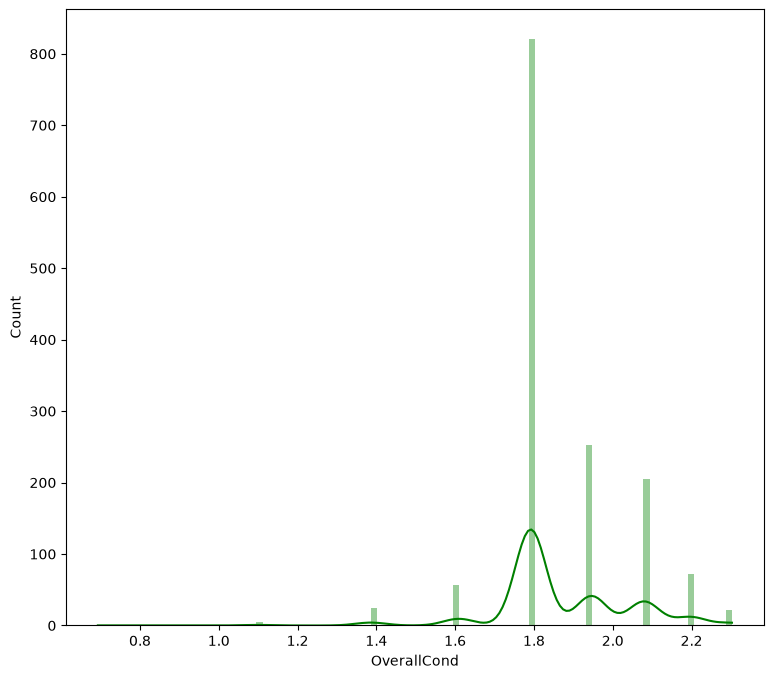

In [8]:
area = train['OverallCond']
area = np.log1p(area)
plt.figure(figsize=(9, 8))
sns.histplot(area, color='g', bins=100, kde=True, alpha=0.4, edgecolor='none')
plt.show()

/Users/ilnik94/Documents/Py/kaggle_house/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


эпох: 400
loss первая / последняя: 131.7017 / 0.4606


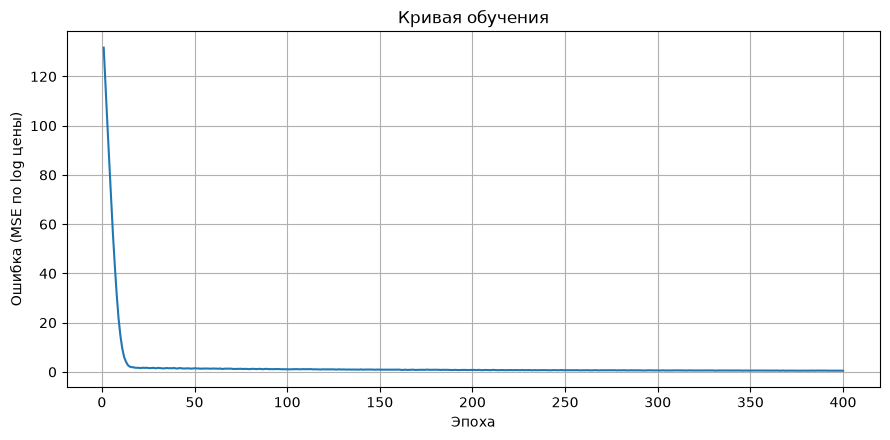

In [11]:
import importlib

import numpy as np

import src.eda as eda
import src.models.mlp as mlp
from config import config
from main import prepare
from src.data import load_data

importlib.reload(mlp)
importlib.reload(eda)

train, test = load_data(config)
df_train, features, test_ids, df_test = prepare(train, test, config)

X_train = df_train[features]
y_train = np.log1p(df_train[config.columns.target])

engine = mlp.ModelEngine(
    lr=config.mlp.lr,
    epochs=config.mlp.epochs,
    batch_size=config.mlp.batch_size,
    seed=config.general.seed,
)
engine.fit(X_train, y_train)
print(f"эпох: {len(engine.loss_history)}")
print(
    f"loss первая / последняя: {engine.loss_history[0]:.4f} / {engine.loss_history[-1]:.4f}"
)
eda.plot_loss_curve(engine.loss_history)

In [ ]:
# Смотрим пропуске в тестовом сете 
train, test = load_data(config)
df_train, features, test_ids, df_test = prepare(train, test, config)

holes = df_test[features].isna()
print(holes.sum()[holes.sum() > 0])

bad = holes.any(axis=1)
print(df_test.loc[bad, ["GarageCars", "GarageArea", "TotalBsmtSF", "BsmtFullBath"]])
print(test_ids.loc[bad])

GarageCars    1
GarageArea    1
dtype: int64
      GarageCars  GarageArea  TotalBsmtSF  BsmtFullBath
1116         NaN         NaN        859.0           0.0
1116    2577
Name: Id, dtype: int64


/Users/ilnik94/Documents/Py/kaggle_house/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [ ]:
# 1. Находим дома, у которых пропущена вместимость машин ИЛИ площадь гаража
garage_nan_mask = test["GarageCars"].isna() | (test["GarageArea"].isna())

# 2. Выбираем все связанные признаки (числа, тексты, качество) для полной картины
garage_inspect_cols = ["Id", "GarageType", "GarageCars", "GarageArea", "GarageQual", "OverallQual"]

# 3. Выводим аномальные строки на экран
print(test.loc[garage_nan_mask, garage_inspect_cols])

train_detchd_stats = test.loc[train['GarageType'] == "Detchd",  ["GarageCars", "GarageArea"]].median()
print(train_detchd_stats)


        Id GarageType  GarageCars  GarageArea GarageQual  OverallQual
1116  2577     Detchd         NaN         NaN        NaN            5
GarageCars      2.0
GarageArea    470.0
dtype: float64
